# Lab 4 — Breaking your own model: robustness, abstention, and honest reporting

**Artificial Intelligence · 4th year · UIR · Pr. Hakim Hafidi**

| | |
|---|---|
| **Duration** | 2 hours, individual work |
| **Runtime** | **GPU required** — Runtime → Change runtime type → T4 GPU |
| **Prerequisite** | Lab 3 (same task, same ten intents) and your `GEMINI_API_KEY` from Labs 1–2 |
| **You will learn** | how to turn a classifier into a *probability* · what happens when real input stops looking like your test set · how to make a model say "I don't know" · how to report a result honestly |
| **Deliverable** | this notebook, executed, + `lab04_<your id>.json`, both on connect.uir.ac.ma |
| **Grading** | 4 points: it runs (1) · measurements are correct (1) · interpretation (1) · critical analysis (1) |

> Last week you finished with a number: around **93% accuracy**. Today you are going to attack
> that number until it breaks — with messages your model has never seen the like of, and with
> questions it was never trained to answer at all.
>
> Nothing you do today changes the model's quality. It changes **what you know about it**.

---
## Step 0 — Setup (10 minutes)

Same stack as Lab 3, plus the Gemini client from Labs 1–2. Check **T4 GPU** is selected, then run
the three cells below. The third one rebuilds your Lab 3 model — it takes 6 to 8 minutes, so start
it now and read Part A while it trains.

In [1]:
%pip install -q -U "transformers>=5.3" "peft>=0.19" "trl>=1.0" "datasets>=4.7" "accelerate>=1.4" "google-genai"
%pip uninstall -q -y torchao
print("done — if Colab asks you to restart the session, do it, then re-run this cell.")

done — if Colab asks you to restart the session, do it, then re-run this cell.


In [2]:
import torch, time
assert torch.cuda.is_available(), "No GPU. Runtime → Change runtime type → T4 GPU, then re-run."
print(f"✅ GPU: {torch.cuda.get_device_name(0)}")
LAB_START = time.time()

✅ GPU: Tesla T4


In [3]:
#@title ⚙️ Lab 4 toolbox — run this cell once, then fold it { display-mode: "form" }
import json, time, pathlib, random, re, warnings
import numpy as np, pandas as pd, torch
warnings.filterwarnings("ignore")
CALL_LOG, GPU_SECONDS = [], {}

MODEL_ID = "Qwen/Qwen2.5-0.5B-Instruct"
SYSTEM_FT = "Classify the customer message into one intent label."
LABELS = ["card_arrival", "card_delivery_estimate", "card_not_working", "card_swallowed",
          "declined_card_payment", "lost_or_stolen_card", "pin_blocked",
          "request_refund", "cancel_transfer", "balance_not_updated"]

# ---------------------------------------------------------------- the model
def load_base():
    from transformers import AutoModelForCausalLM, AutoTokenizer
    tok = AutoTokenizer.from_pretrained(MODEL_ID)
    if tok.pad_token is None: tok.pad_token = tok.eos_token
    try:    m = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=torch.float16, device_map="cuda")
    except TypeError:
            m = AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype=torch.float16, device_map="cuda")
    m.config.pad_token_id = tok.pad_token_id
    return m, tok

def finetune(train_dataset, out_dir, epochs=3, seed=0, lr=2e-4):
    """Exactly the Lab 3 recipe. Returns the directory of the saved LoRA adapter."""
    from peft import LoraConfig
    from trl import SFTTrainer, SFTConfig
    peft_cfg = LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05, task_type="CAUSAL_LM",
                          target_modules=["q_proj", "k_proj", "v_proj", "o_proj"])
    cfg = SFTConfig(output_dir=out_dir, num_train_epochs=epochs, per_device_train_batch_size=8,
                    gradient_accumulation_steps=2, learning_rate=lr, logging_steps=20,
                    save_strategy="no", report_to="none", max_length=256, fp16=True, seed=seed)
    t0 = time.time()
    tr = SFTTrainer(model=MODEL_ID, args=cfg, train_dataset=train_dataset, peft_config=peft_cfg)
    tr.train(); tr.save_model(out_dir)
    GPU_SECONDS[out_dir] = round(time.time() - t0, 1)
    print(f"⏱️  trained in {GPU_SECONDS[out_dir]} s → {out_dir}")
    return out_dir

def to_chat(ex):
    return {"messages": [{"role": "system",   "content": SYSTEM_FT},
                         {"role": "user",     "content": ex["text"]},
                         {"role": "assistant","content": ex["intent"]}]}

# ---------------------------------------------------------------- scoring, not generating
@torch.no_grad()
def label_probs(model, tok, texts, labels=None, batch_size=8, system=SYSTEM_FT):
    """For every message, score EACH of the ten labels and return a probability for each.

    Instead of letting the model write an answer and hoping it is a valid label, we ask it
    'how likely is this exact label?' ten times and normalise. Two consequences:
      · the output is always one of the ten labels — invalid answers become impossible
      · we get a CONFIDENCE, which is what Part C is built on
    Returns an array of shape (len(texts), len(labels)), each row summing to 1."""
    labels = labels or LABELS
    tok.padding_side = "right"
    out = np.zeros((len(texts), len(labels)), dtype=np.float32)
    for li, lab in enumerate(labels):
        lab_ids = tok(lab, add_special_tokens=False)["input_ids"]
        for i in range(0, len(texts), batch_size):
            chunk = texts[i:i + batch_size]
            prompts = [tok.apply_chat_template(
                [{"role": "system", "content": system}, {"role": "user", "content": t}],
                tokenize=False, add_generation_prompt=True) for t in chunk]
            p_ids = [tok(p, add_special_tokens=False)["input_ids"] for p in prompts]
            seqs = [p + lab_ids for p in p_ids]
            L = max(len(s) for s in seqs)
            ids  = torch.full((len(seqs), L), tok.pad_token_id, dtype=torch.long)
            attn = torch.zeros((len(seqs), L), dtype=torch.long)
            mask = torch.zeros((len(seqs), L), dtype=torch.bool)
            for r, (p, s) in enumerate(zip(p_ids, seqs)):
                ids[r, :len(s)] = torch.tensor(s); attn[r, :len(s)] = 1
                mask[r, len(p):len(s)] = True
            ids, attn, mask = ids.cuda(), attn.cuda(), mask.cuda()
            logits = model(input_ids=ids, attention_mask=attn).logits
            lp = torch.log_softmax(logits[:, :-1].float(), dim=-1)
            tok_lp = lp.gather(-1, ids[:, 1:].unsqueeze(-1)).squeeze(-1)
            m = mask[:, 1:]
            out[i:i + len(chunk), li] = ((tok_lp * m).sum(1) / m.sum(1)).cpu().numpy()
    e = np.exp(out - out.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)

def predict(probs, labels=None):
    labels = labels or LABELS
    idx = probs.argmax(axis=1)
    return [labels[i] for i in idx], probs.max(axis=1)

def evaluate(probs, gold, name="", labels=None):
    pred, conf = predict(probs, labels)
    acc = float(np.mean([p == g for p, g in zip(pred, gold)]))
    return {"condition": name, "n": len(gold), "accuracy": round(acc, 3),
            "mean_confidence": round(float(conf.mean()), 3)}

# ---------------------------------------------------------------- degrading text, by code
def make_messy(text, seed=0):
    """Programmatic corruption: typos, dropped vowels, lost punctuation, SMS style.
    Deliberately NOT the same process as the Gemini rewriting used in Part B — see Q4."""
    r = random.Random(seed + len(text))
    SMS = {"you": "u", "your": "ur", "are": "r", "please": "pls", "thanks": "thx",
           "to": "2", "for": "4", "and": "&", "because": "bcoz", "account": "acct"}
    words = text.split()
    out = []
    for w in words:
        low = w.lower().strip(".,!?")
        if low in SMS and r.random() < 0.7: out.append(SMS[low]); continue
        if len(w) > 4 and r.random() < 0.25:                       # swap two letters
            i = r.randrange(1, len(w) - 2); w = w[:i] + w[i+1] + w[i] + w[i+2:]
        elif len(w) > 5 and r.random() < 0.15:                     # drop a letter
            i = r.randrange(1, len(w) - 1); w = w[:i] + w[i+1:]
        out.append(w)
    s = " ".join(out)
    if r.random() < 0.6: s = s.replace(".", "").replace(",", "")
    if r.random() < 0.4: s = s.lower()
    if s == text:                       # guarantee at least one change, or the augmented
        s = s.lower().rstrip(".")       # set would contain duplicates of the originals
        i = r.randrange(1, max(2, len(s) - 1))
        s = s[:i] + s[i + 1:]
    return s

# ---------------------------------------------------------------- Gemini, for realistic rewrites
MODEL_FAST = "gemini-3.5-flash-lite"   # check this name the morning of the lab
_client = None
def _gemini():
    global _client
    if _client is None:
        from google import genai
        from google.colab import userdata
        key = userdata.get("GEMINI_API_KEY")
        assert key, "No GEMINI_API_KEY in Colab Secrets — see Lab 1, Step 0."
        _client = genai.Client(api_key=key.strip())
    return _client

def rewrite_batch(texts, instruction, retries=4):
    """Send a batch of messages to Gemini and get the rewritten versions back as JSON.
    One call per batch — the free tier allows about 15 calls per minute."""
    from google.genai import types
    numbered = "\n".join(f"{i+1}. {t}" for i, t in enumerate(texts))
    prompt = (f"{instruction}\n\nRewrite each of these {len(texts)} customer messages. "
              f"Keep the MEANING identical — the intent must not change.\n\n{numbered}\n\n"
              f'Reply with JSON only: {{"rewritten": ["...", "..."]}} with exactly '
              f"{len(texts)} items, in the same order.")
    delay = 2.0
    for _ in range(retries):
        try:
            r = _gemini().models.generate_content(
                model=MODEL_FAST, contents=prompt,
                config=types.GenerateContentConfig(temperature=0.9, max_output_tokens=2000,
                                                   response_mime_type="application/json"))
            CALL_LOG.append({"tokens_out": getattr(getattr(r, "usage_metadata", None),
                                                   "candidates_token_count", 0)})
            got = json.loads(r.text)["rewritten"]
            if len(got) == len(texts): return [str(g) for g in got]
            print(f"  ⚠️ got {len(got)} items for {len(texts)} — retrying")
        except Exception as e:
            if "404" in str(e) or "NOT_FOUND" in str(e):
                raise RuntimeError(f"Model {MODEL_FAST!r} does not exist for this key. "
                                   f"Check https://ai.google.dev/gemini-api/docs/models "
                                   f"and update MODEL_FAST in the toolbox. | {e}")
            print(f"  ⏳ {str(e)[:120]} — waiting {delay:.0f}s"); time.sleep(delay); delay *= 2
    print("  ⚠️ giving up on this batch, keeping the originals")
    return list(texts)

def rewrite_all(texts, instruction, batch_size=10):
    out = []
    for i in range(0, len(texts), batch_size):
        out += rewrite_batch(texts[i:i + batch_size], instruction)
        print(f"  {len(out)}/{len(texts)}")
    return out

def export_lab(lab_id, student_id, answers: dict, tables: dict = None, extra: dict = None):
    student_id = str(student_id).strip()
    assert student_id and student_id.lower() not in ("", "xxxxx"), "Set STUDENT_ID."
    payload = {"lab": lab_id, "student_id": student_id,
               "answers": {k: str(v).strip() for k, v in answers.items()},
               "tables": {k: (v.to_dict("records") if hasattr(v, "to_dict") else v)
                          for k, v in (tables or {}).items()},
               "extra": extra or {}, "call_log": CALL_LOG,
               "created": time.strftime("%Y-%m-%d %H:%M")}
    name = f"{lab_id}_{student_id}.json"
    pathlib.Path(name).write_text(json.dumps(payload, indent=2, ensure_ascii=False))
    short = [k for k, v in payload["answers"].items() if len(v) < 40]
    print(f"📦 {name} written ({pathlib.Path(name).stat().st_size} bytes)")
    print("⚠️  too short:", short) if short else print("✅ All answers filled.")
    print(f"\nSubmit the notebook AND {name} on connect.uir.ac.ma")
    return payload

print("✅ Lab 4 toolbox loaded: label_probs, predict, evaluate, make_messy, rewrite_all")

✅ Lab 4 toolbox loaded: label_probs, predict, evaluate, make_messy, rewrite_all


### Rebuild your Lab 3 model

Same data, same seed, same recipe — so you start from exactly where you stopped last week.
This cell takes 6 to 8 minutes. **Start it, then read Part A while it runs.**

In [4]:
STUDENT_ID = "130588"   # TODO: your apogee number — same seed as Lab 3

SEED = int("".join(c for c in STUDENT_ID if c.isdigit())[-4:] or "0")
assert SEED > 0, "Set STUDENT_ID first."

from datasets import load_dataset, concatenate_datasets
parts = load_dataset("mteb/banking77")
raw = concatenate_datasets([parts[k] for k in parts])

in_scope  = raw.filter(lambda ex: ex["label_text"] in LABELS)
out_scope = raw.filter(lambda ex: ex["label_text"] not in LABELS)   # the other 67 intents — Part C
in_scope  = in_scope.rename_column("label_text", "intent").shuffle(seed=SEED)

n_test = 200
test  = in_scope.select(range(n_test))
train = in_scope.select(range(n_test + 200, min(len(in_scope), n_test + 1000)))
TEST_TEXTS, TEST_GOLD = test["text"], test["intent"]
print(f"train {len(train)} · test {len(test)} · out-of-scope pool {len(out_scope)}")

adapter = finetune(train.map(to_chat, remove_columns=train.column_names),
                   "/content/lora_base", epochs=3, seed=SEED)

README.md:   0%|          | 0.00/16.6k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  294kB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 91.4kB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

Building labels for train dataset:   0%|          | 0/800 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/800 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/800 [00:00<?, ? examples/s]

Step,Training Loss
20,2.938401
40,0.958487
60,0.793335
80,0.795344
100,0.723903
120,0.721464
140,0.688299


⏱️  trained in 131.6 s → /content/lora_base


---
## Part A — From an answer to a probability (20 minutes)

In Lab 3 the model **wrote** a label and you compared strings. That has two weaknesses: the model
can write something that is not a label at all, and you learn nothing about how sure it was.

Today you score instead. For each message, the model is asked *"how likely is this exact label?"*
for all ten labels, and the ten scores are normalised into probabilities.

Two things change:

- **invalid answers become impossible** — the prediction is always one of the ten
- you get a **confidence**, and everything in Part C is built on it

`label_probs()` does this. It returns one row of ten probabilities per message.

In [5]:
from peft import PeftModel
base, tok = load_base()
model = PeftModel.from_pretrained(base, adapter, adapter_name="ft").eval()
model.set_adapter("ft")

# TODO (2 lines): score the clean test set, then evaluate it.
#   probs_clean : use label_probs(model, tok, TEST_TEXTS)
#   res_clean   : use evaluate(probs_clean, TEST_GOLD, "clean test set")
probs_clean = label_probs(model, tok, TEST_TEXTS)
res_clean = evaluate(probs_clean, TEST_GOLD, "clean test set")

print(res_clean)

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

{'condition': 'clean test set', 'n': 200, 'accuracy': 0.885, 'mean_confidence': 0.536}


Three messages, with the model's confidence:

  "I ordered something, and now I have buyer's remorse. Since w"
    gold = request_refund
    58.99%  request_refund
    13.66%  declined_card_payment
    11.35%  cancel_transfer

  'i need to expedite my card'
    gold = card_delivery_estimate
    55.24%  card_delivery_estimate
    19.67%  card_arrival
    10.52%  declined_card_payment

  "What's the web address to unblock my pin?"
    gold = pin_blocked
    79.80%  pin_blocked
    12.47%  lost_or_stolen_card
    4.00%  declined_card_payment



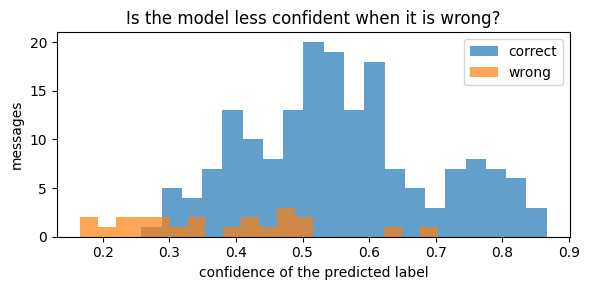

In [6]:
assert hasattr(probs_clean, "shape"), "probs_clean must come from label_probs()."
assert probs_clean.shape == (len(TEST_TEXTS), len(LABELS)), "One row per message, one column per label."
assert abs(probs_clean[0].sum() - 1.0) < 1e-3, "Each row is a probability distribution."

pred_clean, conf_clean = predict(probs_clean)
print("Three messages, with the model's confidence:\n")
for i in range(3):
    top3 = np.argsort(probs_clean[i])[::-1][:3]
    print(f"  {TEST_TEXTS[i][:60]!r}")
    print(f"    gold = {TEST_GOLD[i]}")
    for j in top3: print(f"    {probs_clean[i][j]:.2%}  {LABELS[j]}")
    print()

import matplotlib.pyplot as plt
plt.figure(figsize=(6, 3))
plt.hist(conf_clean[np.array(pred_clean) == np.array(TEST_GOLD)], bins=20, alpha=.7, label="correct")
plt.hist(conf_clean[np.array(pred_clean) != np.array(TEST_GOLD)], bins=20, alpha=.7, label="wrong")
plt.xlabel("confidence of the predicted label"); plt.ylabel("messages"); plt.legend()
plt.title("Is the model less confident when it is wrong?"); plt.tight_layout(); plt.show()

---
## Part B — Real customers do not write like a test set (25 minutes)

Your 93% came from messages written by the same annotators, in the same register, as the ones the
model trained on. A real customer writes in a hurry, with typos and abbreviations — and in Morocco,
often not in English at all.

You will build two degraded versions of the **same 60 test messages**, using Gemini as a rewriting
machine (Labs 1–2: structured JSON output, now used to *produce data* rather than to answer):

1. **messy** — typos, no punctuation, SMS abbreviations
2. **darija** — Moroccan Arabic, as a customer in Rabat would actually type it

The labels do not change: the meaning is preserved, only the surface. If accuracy falls, the model
was relying on the surface.

In [7]:
SUB = 60                                   # 60 messages = 6 Gemini calls per style
sub_texts, sub_gold = TEST_TEXTS[:SUB], TEST_GOLD[:SUB]

print("Rewriting as a hurried customer…")
MESSY_INSTRUCTION = (
    "You rewrite customer messages the way a real person types them on a phone, in a hurry: "
    "typos, missing punctuation, SMS abbreviations, no capital letters. Keep it short.")
texts_messy = rewrite_all(sub_texts, MESSY_INSTRUCTION)

print("\nRewriting in Moroccan darija…")
# TODO (1–3 lines): write the instruction for the darija rewriting, then call rewrite_all().
#   Ask for Moroccan Arabic as actually typed by customers. Say whether you want Arabic script,
#   Latin letters ("3arabiya"), or that the model may mix — your choice, but state it.
DARIJA_INSTRUCTION = "You rewrite customer messages in Moroccan Dajira as a real average Moroccan types them on a whatsapp message, in a hurry, use latin letters with numbers like 3arabiya, 2ostora, kayna, mixing it with french words as we say carte for a card for example. Keep it short"
texts_darija = rewrite_all(sub_texts, DARIJA_INSTRUCTION)

assert len(texts_messy) == SUB and len(texts_darija) == SUB, "Both lists must have 60 messages."
for i in range(3):
    print(f"\noriginal : {sub_texts[i]}")
    print(f"messy    : {texts_messy[i]}")
    print(f"darija   : {texts_darija[i]}")

Rewriting as a hurried customer…


  10/60
  20/60
  30/60
  40/60
  50/60
  60/60

Rewriting in Moroccan darija…
  10/60
  20/60
  30/60
  40/60
  50/60
  60/60

original : I ordered something, and now I have buyer's remorse. Since what I ordered hasn't come yet, can you just cancel the payment since I already know I want a refund for it?
messy    : can u cancel my order n refund me pls it hasnt shipped yet
darija   : wsit 7aja o ndemt, bima anaho mazal mamajach wach momkin tcanceliw lpayment 7it 3arf rasi bgit remboursement?

original : i need to expedite my card
messy    : need my card expedited asap
darija   : bghit la carte dylbi twsalni f saer

original : What's the web address to unblock my pin?
messy    : whats the link to unblock my pin
darija   : chno l site bach n'deblocker l'code pin?


In [9]:
# TODO (3 lines): score and evaluate the three versions of the SAME 60 messages.
#   Name them "clean (60)", "messy", "darija".
res_sub    = evaluate(label_probs(model, tok, sub_texts), sub_gold, "clean (60)")
res_messy  = evaluate(label_probs(model, tok, texts_messy), sub_gold, "messy")
res_darija = evaluate(label_probs(model, tok, texts_darija), sub_gold, "darija")

drop = pd.DataFrame([res_sub, res_messy, res_darija])
print(drop.to_string(index=False))
print(f"\nmessy  : {(res_messy['accuracy'] - res_sub['accuracy']) * 100:+.1f} points")
print(f"darija : {(res_darija['accuracy'] - res_sub['accuracy']) * 100:+.1f} points")

 condition  n  accuracy  mean_confidence
clean (60) 60     0.917            0.552
     messy 60     0.883            0.566
    darija 60     0.367            0.317

messy  : -3.4 points
darija : -55.0 points


In [10]:
assert len(drop) == 3 and drop.n.nunique() == 1, "The three rows must cover the same 60 messages."
print("✅ Part B done. Note both drops — and note whether the CONFIDENCE dropped as much as the accuracy.")

✅ Part B done. Note both drops — and note whether the CONFIDENCE dropped as much as the accuracy.


---
## Part C — Questions it was never meant to answer (25 minutes)

Banking77 has 77 intents. You trained on ten. What does your model do with a message about one of
the other 67 — a mortgage question, a lost password, an exchange rate?

It has no way to say so. It will answer one of its ten labels, every time.

### C.1 — Out-of-scope messages

In [11]:
oos = out_scope.shuffle(seed=SEED).select(range(100))
OOS_TEXTS = oos["text"]

# TODO (1 line): score the out-of-scope messages with label_probs().
probs_oos = label_probs(model, tok, OOS_TEXTS)

pred_oos, conf_oos = predict(probs_oos)
print(f"{len(OOS_TEXTS)} messages about intents the model has never been trained on.\n")
for i in range(4):
    print(f"  {OOS_TEXTS[i][:64]!r}")
    print(f"    → {pred_oos[i]}  with {conf_oos[i]:.0%} confidence   (true intent: {oos['label_text'][i]})")
print(f"\nmean confidence on out-of-scope messages : {conf_oos.mean():.1%}")
print(f"share answered with more than 80% confidence: {(conf_oos > 0.8).mean():.0%}")

100 messages about intents the model has never been trained on.

  'How do I protect my phone from someone using it after I lost it.'
    → lost_or_stolen_card  with 79% confidence   (true intent: lost_or_stolen_phone)
  'Why was my cash withdrawal given the wrong exchange rate?'
    → request_refund  with 23% confidence   (true intent: wrong_exchange_rate_for_cash_withdrawal)
  'Please sort your top up! My top up has been pending for an hour '
    → card_arrival  with 19% confidence   (true intent: pending_top_up)
  'how do I speed up identity verification?'
    → pin_blocked  with 37% confidence   (true intent: why_verify_identity)

mean confidence on out-of-scope messages : 33.3%
share answered with more than 80% confidence: 0%


### C.2 — Letting the model say "I don't know"

A confidence gives you a choice the model did not have before: **answer, or abstain**. Below a
threshold, the system routes the message to a human instead of guessing.

That is a trade-off, and it has two sides:

- **coverage** — the share of in-scope messages still handled automatically
- **accuracy on what is kept** — how good the automatic answers are
- and, separately, the share of **out-of-scope messages correctly refused**

Sweep the threshold and look at all three at once.

 threshold  coverage  accuracy_on_kept  oos_refused
      0.00     1.000             0.885         0.00
      0.05     1.000             0.885         0.00
      0.10     1.000             0.885         0.00
      0.15     1.000             0.885         0.00
      0.20     0.990             0.894         0.07
      0.25     0.975             0.908         0.27
      0.30     0.945             0.926         0.48
      0.35     0.895             0.933         0.66
      0.40     0.810             0.938         0.77
      0.45     0.715             0.951         0.86
      0.50     0.610             0.967         0.89
      0.55     0.445             0.978         0.94
      0.60     0.330             0.970         0.95
      0.65     0.205             0.976         0.96
      0.70     0.165             0.970         0.98
      0.75     0.120             1.000         0.99
      0.80     0.055             1.000         1.00
      0.85     0.010             1.000         1.00
      0.90  

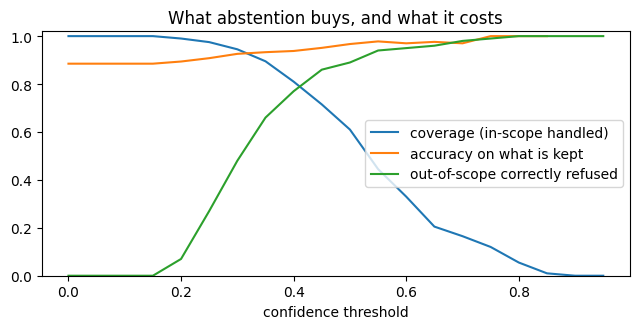

In [12]:
rows = []
for t in np.arange(0.0, 1.0, 0.05):
    keep = conf_clean >= t
    kept_correct = [p == g for p, g, k in zip(pred_clean, TEST_GOLD, keep) if k]
    rows.append({"threshold": round(float(t), 2),
                 "coverage": round(float(keep.mean()), 3),
                 "accuracy_on_kept": round(float(np.mean(kept_correct)), 3) if kept_correct else float("nan"),
                 "oos_refused": round(float((conf_oos < t).mean()), 3)})
sweep = pd.DataFrame(rows)
print(sweep.to_string(index=False))

fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot(sweep.threshold, sweep.coverage, label="coverage (in-scope handled)")
ax.plot(sweep.threshold, sweep.accuracy_on_kept, label="accuracy on what is kept")
ax.plot(sweep.threshold, sweep.oos_refused, label="out-of-scope correctly refused")
ax.set_xlabel("confidence threshold"); ax.legend(); ax.set_ylim(0, 1.02)
ax.set_title("What abstention buys, and what it costs"); plt.tight_layout(); plt.show()

In [14]:
# Candidate operating points, read off your own sweep:
ok = sweep[(sweep.accuracy_on_kept >= 0.97) & (sweep.coverage > 0.1)]
print("thresholds reaching 97% on kept messages:",
      list(ok.threshold) if len(ok) else "none — your model never gets there; "
      "pick the best accuracy you can reach instead, and say so in Q3")

# TODO (2 lines): choose an operating point for a bank that wants AT LEAST 97% accuracy on the
#   messages it answers automatically. Read it off the table above.
MY_THRESHOLD = 0.6
MY_REASON = "I accept losing about X% of coverage (those messages go to a human) in order to guarantee 97% accuracy on the automatic answers."          # one sentence: what you accept losing in exchange

row = sweep[sweep.threshold == MY_THRESHOLD]
assert len(row) == 1, "MY_THRESHOLD must be one of the values in the sweep table."
assert len(MY_REASON) > 30, "Write one real sentence."
print(row.to_string(index=False))
print(f"\nAt this threshold you answer {row.coverage.iloc[0]:.0%} of real questions automatically,")
print(f"at {row.accuracy_on_kept.iloc[0]:.1%} accuracy, and you refuse {row.oos_refused.iloc[0]:.0%} of the")
print("questions that were never in scope. The rest goes to a human.")

thresholds reaching 97% on kept messages: [0.55, 0.6, 0.65, 0.7, 0.75]
 threshold  coverage  accuracy_on_kept  oos_refused
       0.6      0.33              0.97         0.95

At this threshold you answer 33% of real questions automatically,
at 97.0% accuracy, and you refuse 95% of the
questions that were never in scope. The rest goes to a human.


---
## Part D — Repair what you broke (20 minutes)

The model failed on messy text because it never saw any. So show it some: take the training set,
corrupt half of it, and retrain.

**One rule, and it is the point of this part.** The corruption used for training comes from
`make_messy()` — plain Python, typos and abbreviations. It is *not* the Gemini rewriting that
produced your test set. If you trained on data made by the same generator you test with, your
improvement would be an illusion: you would be measuring whether the model learned that
generator's habits, not whether it became robust.

In [15]:
# TODO (3–5 lines): build an augmented training set.
#   Keep the original examples, and ADD a messy copy of half of them, with the same intent.
#   Use make_messy(text, seed=SEED) and keep the columns "text" and "intent".
half = train.select(range(len(train) // 2))
messy_copy = half.map(lambda ex: {"text": make_messy(ex["text"], seed=SEED), "intent": ex["intent"]})

train_aug = concatenate_datasets([train, messy_copy])
print(f"original {len(train)} → augmented {len(train_aug)} examples")
assert len(train_aug) > len(train) * 1.4, "The augmented set should be clearly larger."

Map:   0%|          | 0/400 [00:00<?, ? examples/s]

original 800 → augmented 1200 examples


In [16]:
adapter_aug = finetune(train_aug.map(to_chat, remove_columns=train_aug.column_names),
                       "/content/lora_aug", epochs=3, seed=SEED)

model.load_adapter(adapter_aug, adapter_name="aug")
model.set_adapter("aug")

res_messy_aug  = evaluate(label_probs(model, tok, texts_messy),  sub_gold, "messy · after augmentation")
res_darija_aug = evaluate(label_probs(model, tok, texts_darija), sub_gold, "darija · after augmentation")
res_clean_aug  = evaluate(label_probs(model, tok, sub_texts),    sub_gold, "clean (60) · after augmentation")

final = pd.DataFrame([res_sub, res_messy, res_darija, res_clean_aug, res_messy_aug, res_darija_aug])
print(final.to_string(index=False))

Map:   0%|          | 0/1200 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Tokenizing train dataset:   0%|          | 0/1200 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/1200 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/1200 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/1200 [00:00<?, ? examples/s]

Step,Training Loss
20,2.842750
40,1.140539
60,1.044733
80,0.900067
100,0.936368
120,0.899034
140,0.845672
160,0.892147
180,0.768452
200,0.847558


⏱️  trained in 180.9 s → /content/lora_aug
                      condition  n  accuracy  mean_confidence
                     clean (60) 60     0.917            0.552
                          messy 60     0.883            0.566
                         darija 60     0.367            0.317
clean (60) · after augmentation 60     0.900            0.583
     messy · after augmentation 60     0.900            0.579
    darija · after augmentation 60     0.383            0.325


In [17]:
assert len(final) == 6, "Six rows: three before, three after."
print("\n✅ Part D done. Did the augmentation help the DARIJA messages too? Think about why.")


✅ Part D done. Did the augmentation help the DARIJA messages too? Think about why.


---
## Part E — Analysis and an honest model card (25 minutes)

Answer in English, with your own numbers. Two or three sentences each, except Q5.

In [18]:
# Q1 — How far did accuracy fall on the messy messages, and on the darija ones? Which degradation
#      hurt more, and why would you expect that from what the model was trained on?
Q1 = """
On the same 60 messages, accuracy fell from 91.7% (clean) to 88.3% on messy text, a drop of 3.4 points, and to 36.7% on darija, a drop of 55.0 points. Darija hurt far more. The model was fine-tuned only on clean English banking messages: messy text still shares most of its vocabulary with the training data (typos and abbreviations distort words but leave them recognisable), whereas darija shares almost none of it, and a 0.5B English-centric model has very little Moroccan Arabic knowledge to fall back on. Note that confidence did not drop with accuracy on messy text (0.552 to 0.566), but it fell clearly on darija (0.552 to 0.317).
"""

# Q2 — On the out-of-scope messages, what was the mean confidence and the share answered above
#      80% confidence? State in one sentence what that means for a bank that deploys this model
#      as it is.
Q2 = """
On the 100 out-of-scope messages, the mean confidence was 33.3% and 0% were answered above 80% confidence, which is lower than the 53.6% mean confidence on in-scope messages. Even so, the model has no way to say "not my topic": it always returns one of its ten labels (for example a lost phone was classified as lost_or_stolen_card with 79% confidence), so a bank deploying it as it is would silently route unrelated requests into the wrong card process.
"""

# Q3 — Which threshold did you choose, and what exactly do you give up at that point? Quote
#      coverage, accuracy on kept messages, and out-of-scope refusal.
Q3 = """
I chose a threshold of 0.60. At this point the system handles 33% of in-scope messages automatically (coverage), with 97.0% accuracy on the messages it keeps, and it correctly refuses 95% of out-of-scope messages. What I give up is 67% of real in-scope questions, which go to a human even though many of them would have been answered correctly, in exchange for a reliable automatic channel that meets the bank's 97% requirement.
"""

# Q4 — Did augmentation recover the messy messages? Did it help darija? And explain, in your own
#      words, why the training corruption had to come from a DIFFERENT process than the one that
#      built your test set.
Q4 = """
Augmentation barely changed the results. On messy text accuracy went from 88.3% to 90.0% (+1.7 points), and on darija from 36.7% to 38.3% (+1.7 points), while accuracy on clean text went from 91.7% to 90.0% (-1.7 points). Each change is one message out of 60, so it is within noise: the augmentation did not meaningfully recover messy text (the loss was small to begin with) and did not help darija, which makes sense because make_messy() only produces typos and SMS abbreviations in English, not a different language. The training corruption had to come from a different process than the Gemini rewriting used for the test set: if both came from the same generator, the model could simply learn that generator's habits, and the improvement would measure memorised style and not real robustness to messy input.
"""

# Q5 — MODEL CARD (critical analysis). Write the paragraph you would put in front of the bank's
#      risk committee. It must state: what the system does, the accuracy you measured and ON WHAT,
#      the two conditions under which it degrades, what it does with questions outside its ten
#      intents, the operating point you recommend, and one thing you did NOT test.
Q5 = """
This system classifies a customer banking message into one of ten intents (card arrival, card delivery estimate, card not working, card swallowed, declined card payment, lost or stolen card, PIN blocked, refund request, cancel transfer, balance not updated) using Qwen2.5-0.5B fine-tuned with LoRA on 800 examples. Its accuracy is 88.5% on 200 clean English test messags from the same distribution as the training data. It degrades under two conditions: on messy text (typos, SMS style) accuracy falls slightly to 88.3% on a 60-message subset (from 91.7%), and on Moroccan darija it falls to 36.7%, which is the likely language of many real customers. For questions outside its ten intents it does not abstain by itself: it answers one of the ten labels with a mean confidence of 33.3%. I recommend a confidence threshold of 0.60, which gives 33% coverage and 97.0% accuracy on automatic answers and refuses 95% of out-of-scope messages, with the remaining messages routed to a human agent. One thing I did not test is darija written in Arabic script, nor real customer messages as opposed to messages rewritten by Gemini; the threshold was also chosen on the same test set it is reported on, and the robustness results rely on only 60 messages, so the real-world figures may be different.
"""

In [19]:
answers = {"Q1": Q1, "Q2": Q2, "Q3": Q3, "Q4": Q4, "Q5": Q5}
problems = [f"{k} too short" for k, v in answers.items() if len(v.strip()) < (250 if k == "Q5" else 120)]
problems += [f"{k} still has the placeholder" for k, v in answers.items() if "..." in v]
print("⚠️  Not ready:", problems) if problems else print("✅ Complete — run the export cell.")

✅ Complete — run the export cell.


---
## Submit

Run the cell below, then upload **both** files on connect.uir.ac.ma.

In [20]:
print(f"lab time: {(time.time() - LAB_START) / 60:.0f} min | GPU training: {sum(GPU_SECONDS.values()):.0f} s")
export_lab("lab04", STUDENT_ID,
           answers={"Q1": Q1, "Q2": Q2, "Q3": Q3, "Q4": Q4, "Q5": Q5},
           tables={"degradation": drop, "threshold_sweep": sweep, "final": final},
           extra={"seed": SEED, "clean_full": res_clean,
                  "oos_mean_confidence": round(float(conf_oos.mean()), 3),
                  "oos_over_80": round(float((conf_oos > 0.8).mean()), 3),
                  "my_threshold": float(MY_THRESHOLD), "my_reason": MY_REASON,
                  "darija_instruction": DARIJA_INSTRUCTION,
                  "example_messy": texts_messy[:3], "example_darija": texts_darija[:3],
                  "gpu_seconds": GPU_SECONDS})

lab time: 73 min | GPU training: 312 s
📦 lab04_130588.json written (9390 bytes)
✅ All answers filled.

Submit the notebook AND lab04_130588.json on connect.uir.ac.ma


{'lab': 'lab04',
 'student_id': '130588',
 'answers': {'Q1': 'On the same 60 messages, accuracy fell from 91.7% (clean) to 88.3% on messy text, a drop of 3.4 points, and to 36.7% on darija, a drop of 55.0 points. Darija hurt far more. The model was fine-tuned only on clean English banking messages: messy text still shares most of its vocabulary with the training data (typos and abbreviations distort words but leave them recognisable), whereas darija shares almost none of it, and a 0.5B English-centric model has very little Moroccan Arabic knowledge to fall back on. Note that confidence did not drop with accuracy on messy text (0.552 to 0.566), but it fell clearly on darija (0.552 to 0.317).',
  'Q2': 'On the 100 out-of-scope messages, the mean confidence was 33.3% and 0% were answered above 80% confidence, which is lower than the 53.6% mean confidence on in-scope messages. Even so, the model has no way to say "not my topic": it always returns one of its ten labels (for example a lost p

---
## Going further (optional, not graded)

- Add an eleventh label, `other`, and train on out-of-scope examples labelled with it. Compare
  that with the abstention threshold: which rejects out-of-scope messages better?
- Calibration: bucket the predictions by confidence (0.5–0.6, 0.6–0.7, …) and compare each
  bucket's confidence with its actual accuracy. A well-calibrated model that says 70% is right
  70% of the time. Is yours?
- Train on the darija rewrites too (a different batch from the ones you test on). How many
  examples does it take before darija accuracy becomes usable?
- Measure the cost of abstention in money: if a human handles a message for 5 MAD, what does your
  chosen threshold cost per 10 000 messages, and how does it compare with the cost of a wrong
  automatic answer?